In [77]:
import pandas as pd 
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score,classification_report
from sklearn.model_selection import train_test_split

In [78]:
df = pd.read_csv("shop_smart_ecommerce.csv")

In [79]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [80]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [81]:
# Data Pre-Processing Categorical -> Numerical


# boolian to int 
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

# .map() -> manual mapping -> assigns numbers according to a meaningful order.
month_order = {
    "Jan": 1, "Feb": 2, "Mar": 3,
    "Apr": 4, "May": 5, "June": 6,
    "Jul": 7, "Aug": 8, "Sep": 9,
    "Oct": 10, "Nov": 11, "Dec": 12
}

df["Month"] = df["Month"].map(month_order)

# one - hot encoding ->create separate binary columns ->used for unordered category
df = pd.get_dummies(
    df,
    columns=["VisitorType"],
    dtype=int
)

In [82]:
x = df.drop("Revenue", axis=1)
y = df["Revenue"]

In [83]:
x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [84]:
model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

F1-Score: 56.763285024154584 %
Benchmark is Achieved


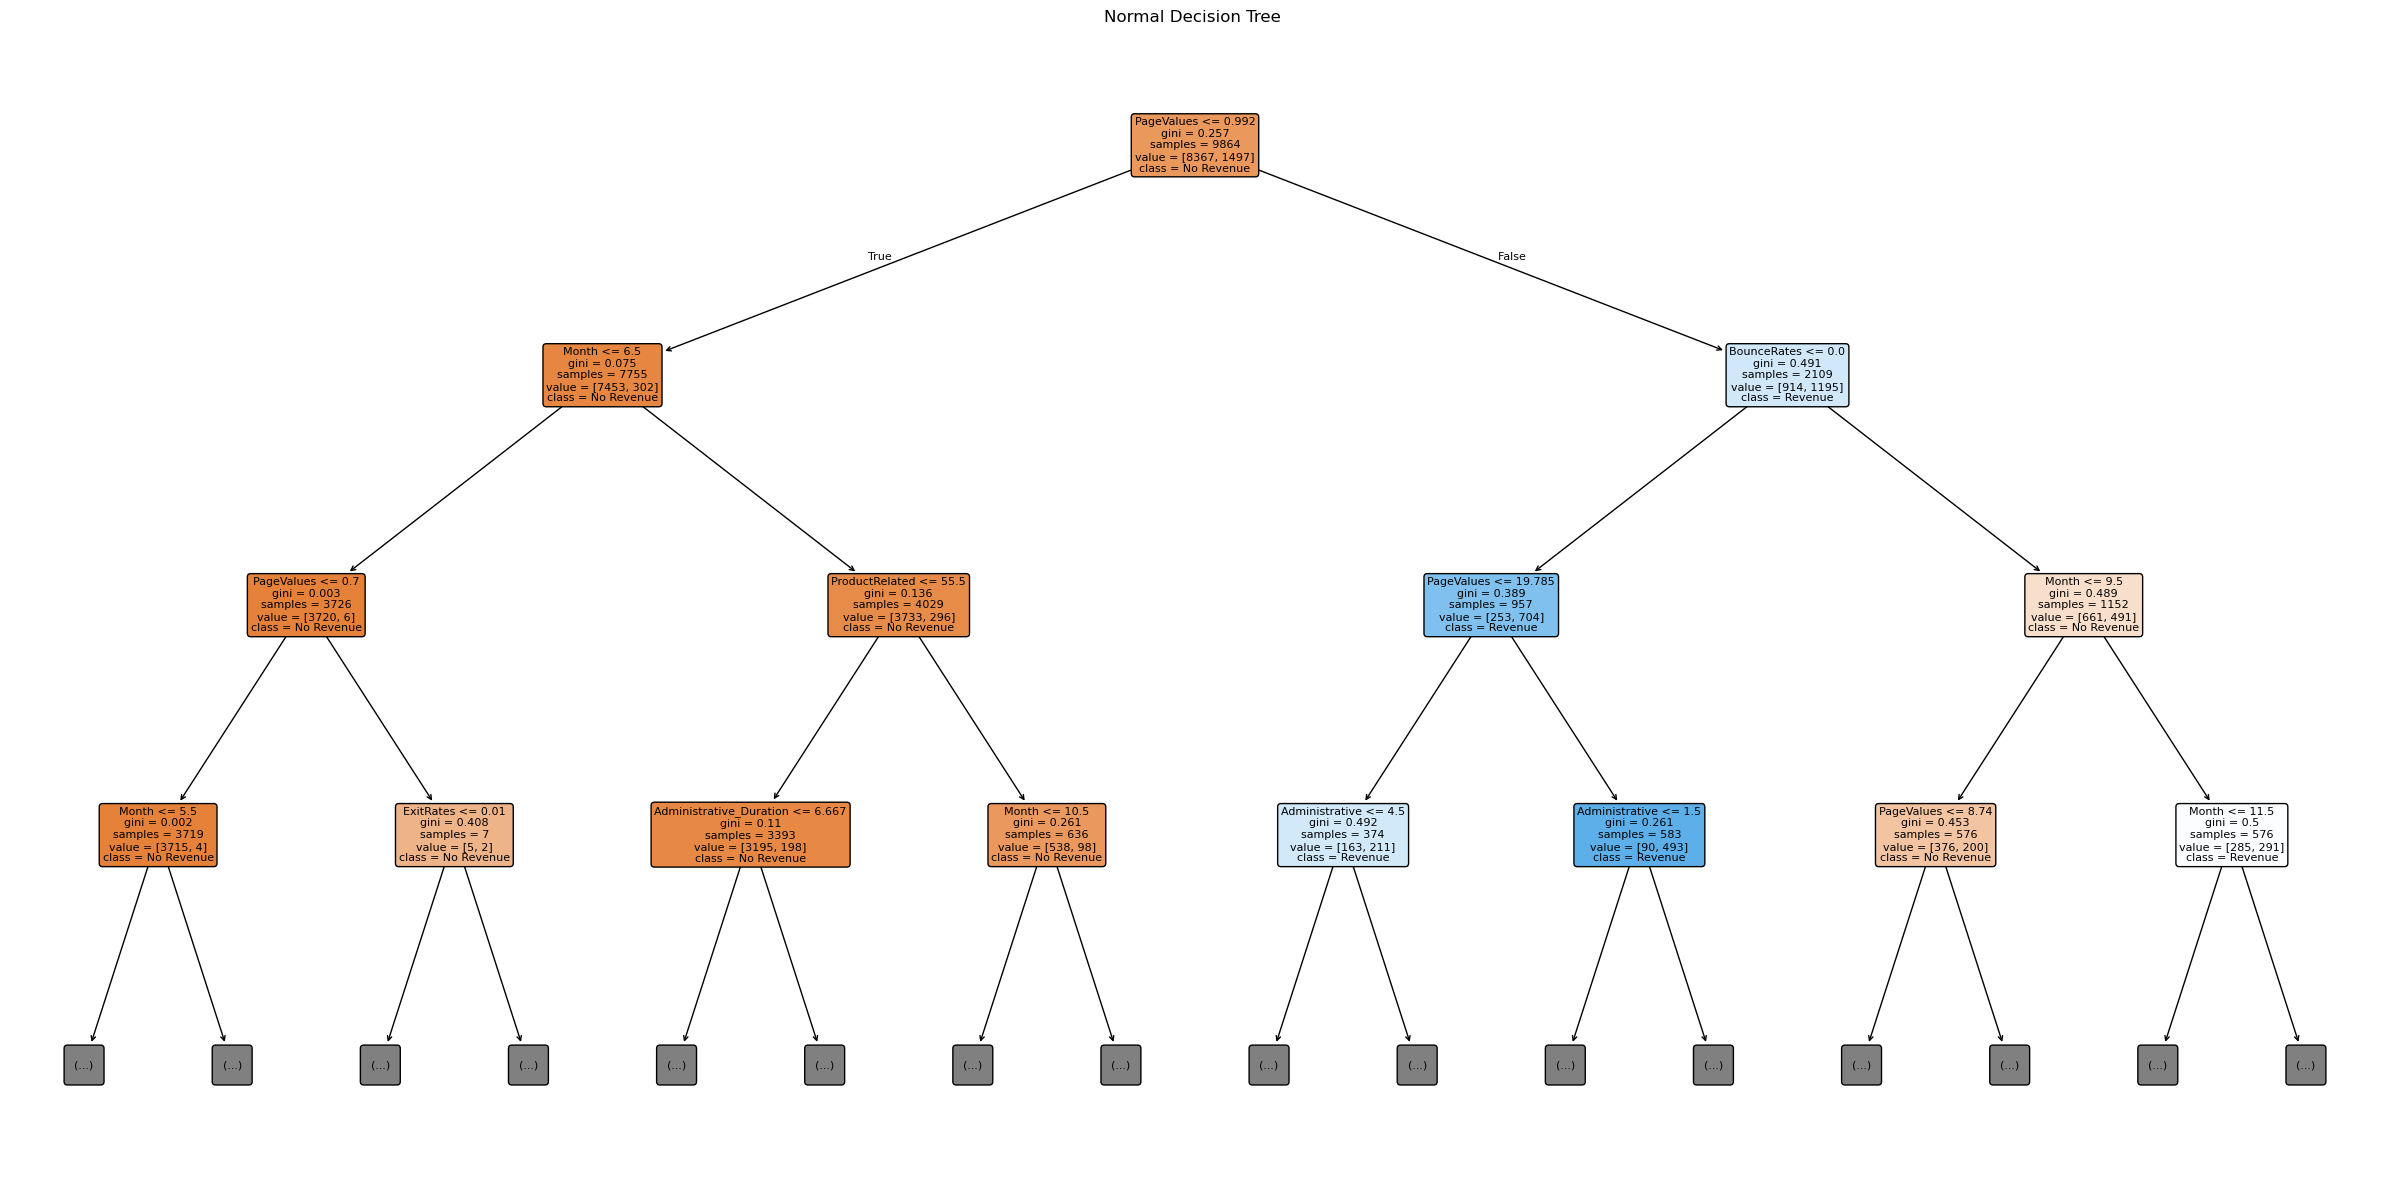

In [89]:
y_predict=model.predict(x_test)

print("F1-Score:", f1_score(y_test,y_predict)*100 ,"%")

f1=f1_score(y_test,y_predict)
if(f1>=0.55):
    print("Benchmark is Achieved")
else:
    print("Benchmark is not Achieved")



# Plot Tree

from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=x_train.columns,
    class_names=["No Revenue", "Revenue"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Normal Decision Tree ")
plt.tight_layout()
plt.show()


Best Parameters: {'max_depth': 3, 'min_samples_split': 3}
Best CV F1 Score: 1
F1-Score: 63.55611601513241 %
Benchmark is Achieved


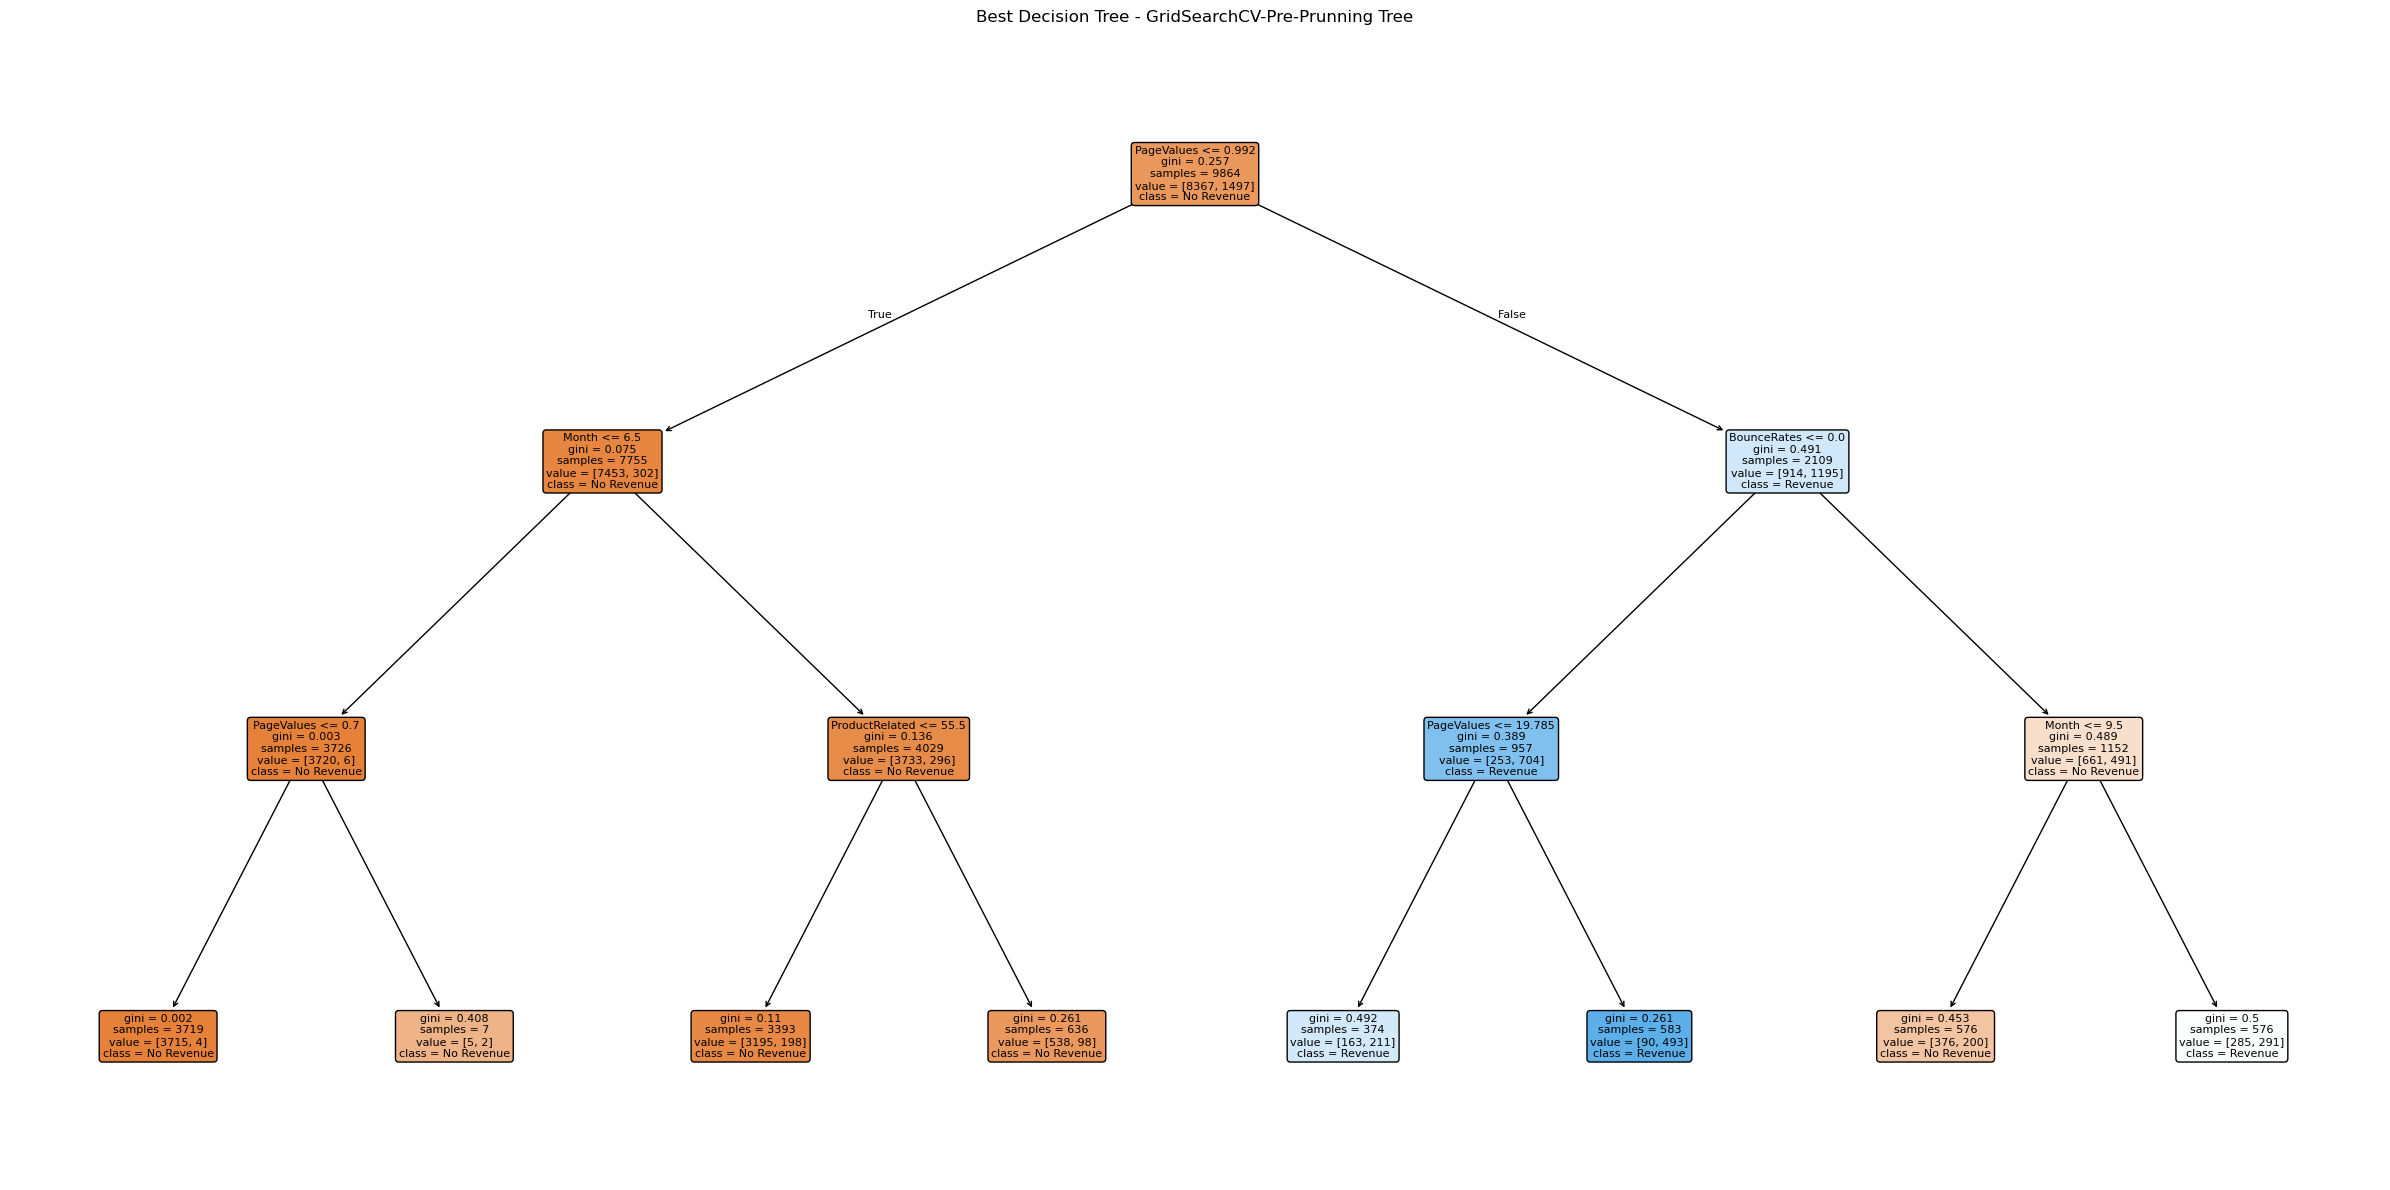

In [88]:
# Pre-Prunning using depth and sample
from sklearn.model_selection import GridSearchCV

depth = [3,5,8,10,12,15,20,50]
sample = [3,5,8,10,12,15,20,50]

# Define hyperparameters
param_grid = {
    "max_depth": depth,
    "min_samples_split": sample
}

# Create model
dt = DecisionTreeClassifier(random_state=42)

# Grid Search
grid = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid.fit(x_train, y_train)   #Searches, selects parameters, and fits the final model

print("Best Parameters:", grid.best_params_)  # Returns the selected parameters
print("Best CV F1 Score:", round(grid.best_score_))  # return best average cross-validation F1-score.

best_model = grid.best_estimator_    # OR      # Returns the already-trained best model
y_predict = best_model.predict(x_test)


print("F1-Score:", f1_score(y_test,y_predict)*100 ,"%")

f1=f1_score(y_test,y_predict)
if(f1>=0.55):
    print("Benchmark is Achieved")
else:
    print("Benchmark is not Achieved")



# Plot tree 

plt.figure(figsize=(24, 12))

plot_tree(
    best_model,
    feature_names=x_train.columns,
    class_names=["No Revenue", "Revenue"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Best Decision Tree - GridSearchCV-Pre-Prunning Tree")
plt.tight_layout()
plt.show()

Best F1-Score: 64.04341926729987 %
Max Depth 5
Min Sample for Split: 8
Benchmark achieved!


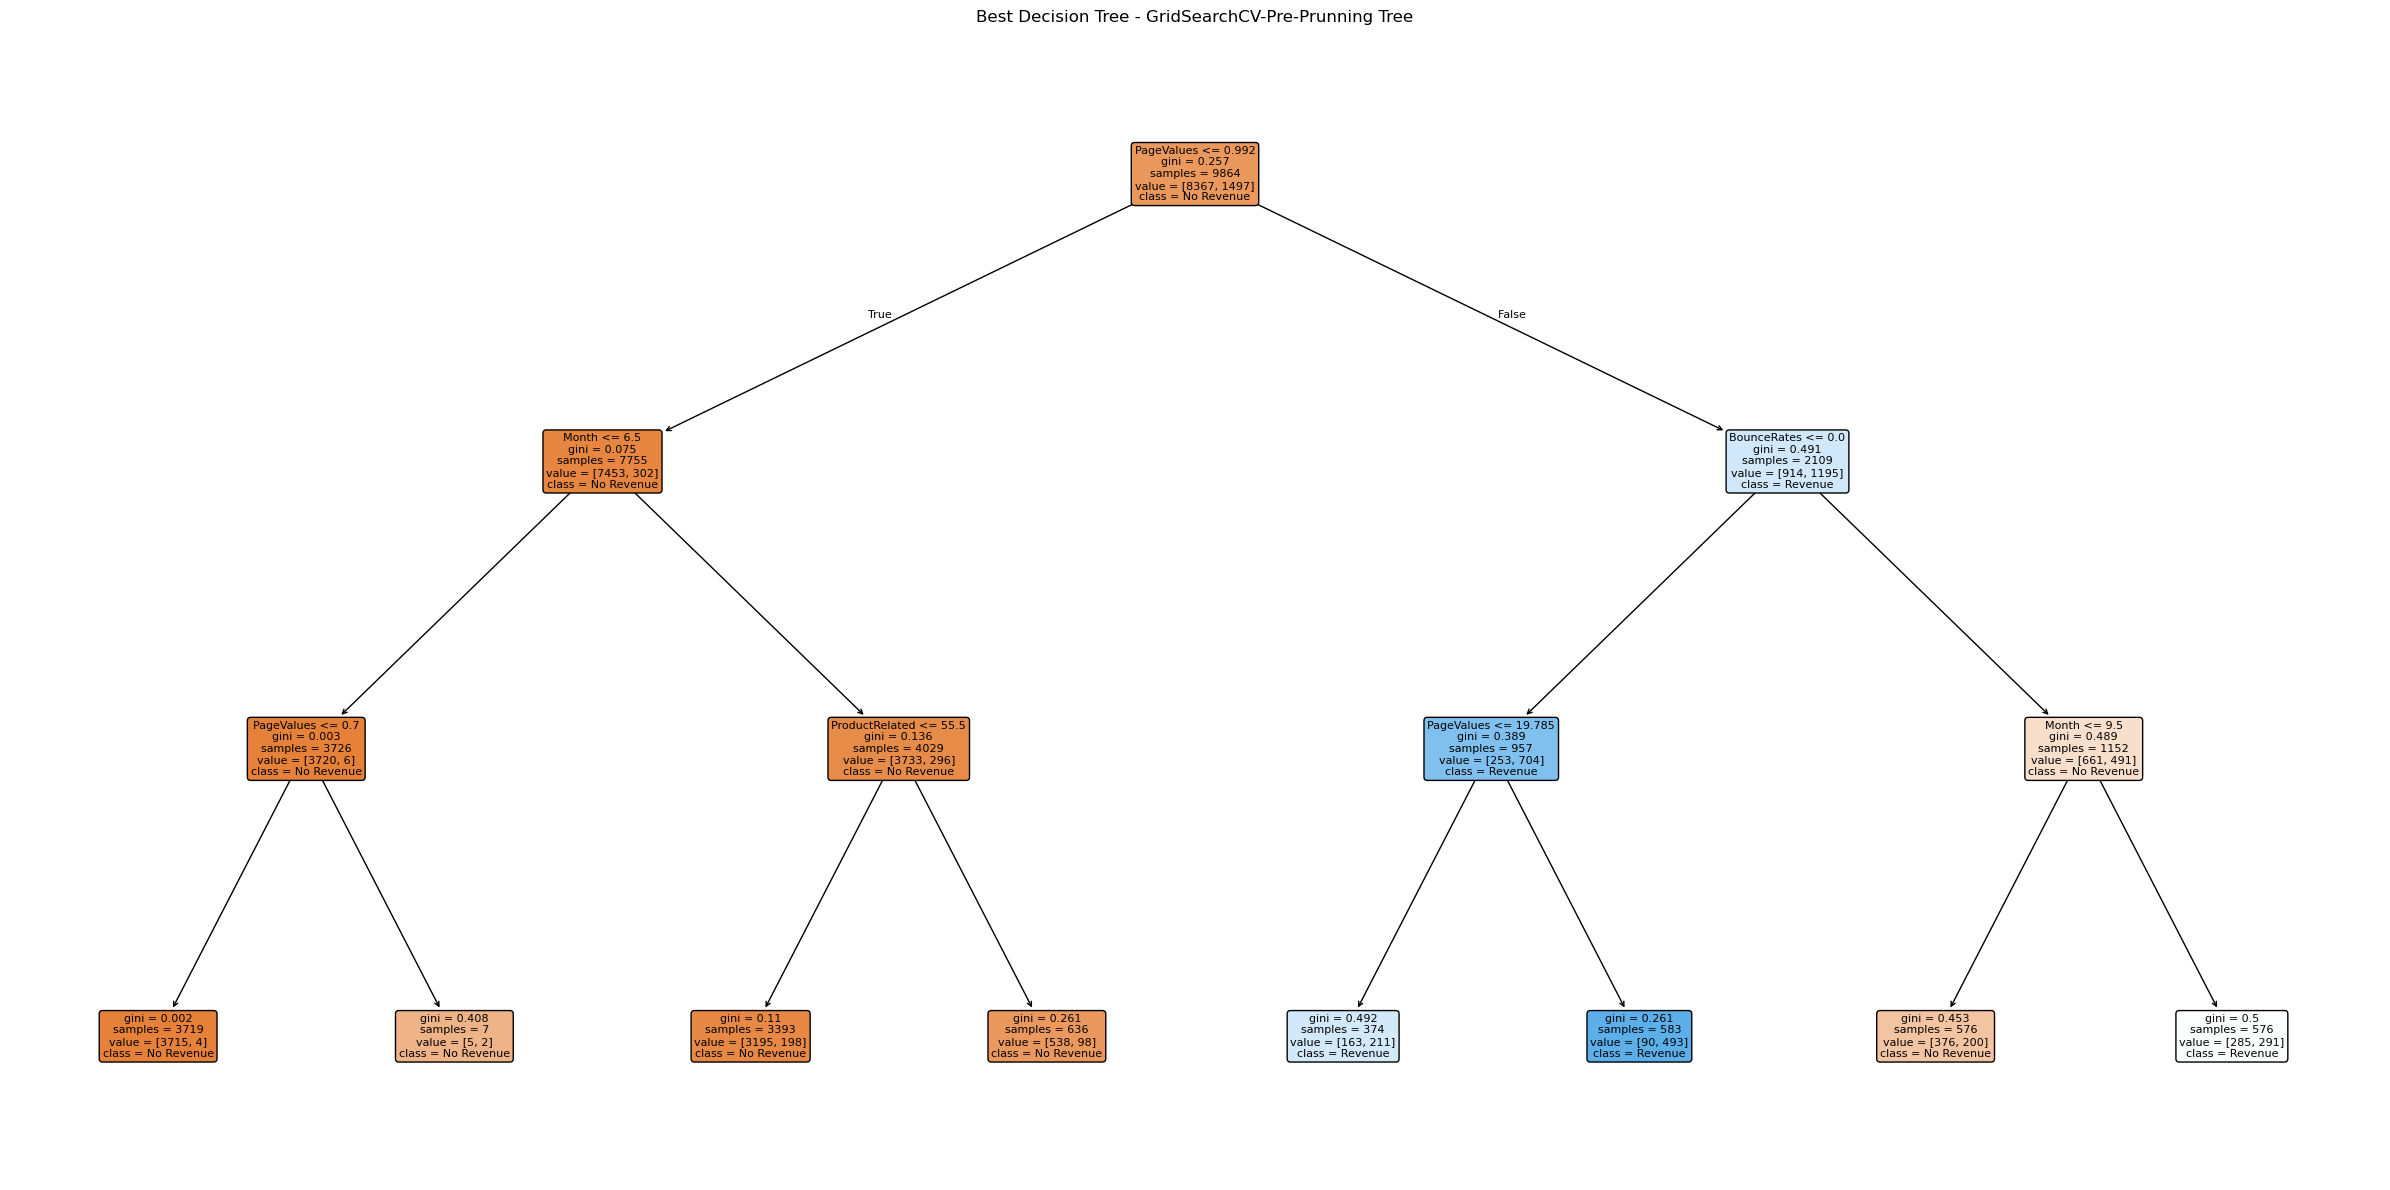

In [90]:
# Manually Select best parameters 

depth = [3,5,8,10,12,15,20,50]
sample = [3,5,8,10,12,15,20,50]

best_f1=0
best_d= None
best_s= None

for d in depth:
    for s in sample:
        model = DecisionTreeClassifier(max_depth=d, min_samples_split=s, random_state=42)

        model.fit(x_train,y_train)
        y_predict = model.predict(x_test)

        f1= f1_score(y_test,y_predict)

        if f1 > best_f1:
            best_f1 = f1
            best_d = d
            best_s = s

print("Best F1-Score:",best_f1*100,"%")
print("Max Depth",best_d)
print("Min Sample for Split:",best_s)

if best_f1 >= 0.55:
    print("Benchmark achieved!")
else:
    print("Benchmark not achieved!")


# Plot tree 

plt.figure(figsize=(24, 12))

plot_tree(
    best_model,
    feature_names=x_train.columns,
    class_names=["No Revenue", "Revenue"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Best Decision Tree - GridSearchCV-Pre-Prunning Tree")
plt.tight_layout()
plt.show()


In [91]:
# Post-Prunning

full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(x_train,y_train)



DecisionTreeClassifier(random_state=42)

In [93]:
path = full_tree.cost_complexity_pruning_path(x_train,y_train)
ccp_alphas = path.ccp_alphas

# print(ccp_alphas)

In [97]:
# manually select best alpha value 

best_f1=0
best_alpha= None

for alpha in ccp_alphas:
    model=DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    
    model.fit(x_train,y_train)
    y_predict=model.predict(x_test)

    f1=f1_score(y_test,y_predict)

    if f1 > best_f1:
        best_f1 = f1
        best_alpha = alpha

print("Best F1-Score:", best_f1*100,"%")
print("Best-Alpha:", best_alpha)
 

Best F1-Score: 67.42502585315408 %
Best-Alpha: 0.010147354849669346


In [105]:
# using Grid Search 


param_grid = {"ccp_alpha": ccp_alphas}

grid=GridSearchCV(
    estimator = full_tree,
    param_grid = param_grid,
    scoring = "f1",
    cv = 5,
    n_jobs = -1 
    
)

grid.fit(x_train,y_train)


print("Best Alpha:", grid.best_params_["ccp_alpha"]) 
print("Best CV F1-Score:", round(grid.best_score_)*100,"%")


Best Alpha: 0.0005075326133508287
Best CV F1-Score: 100 %


F1-score: 64.13043478260869 %


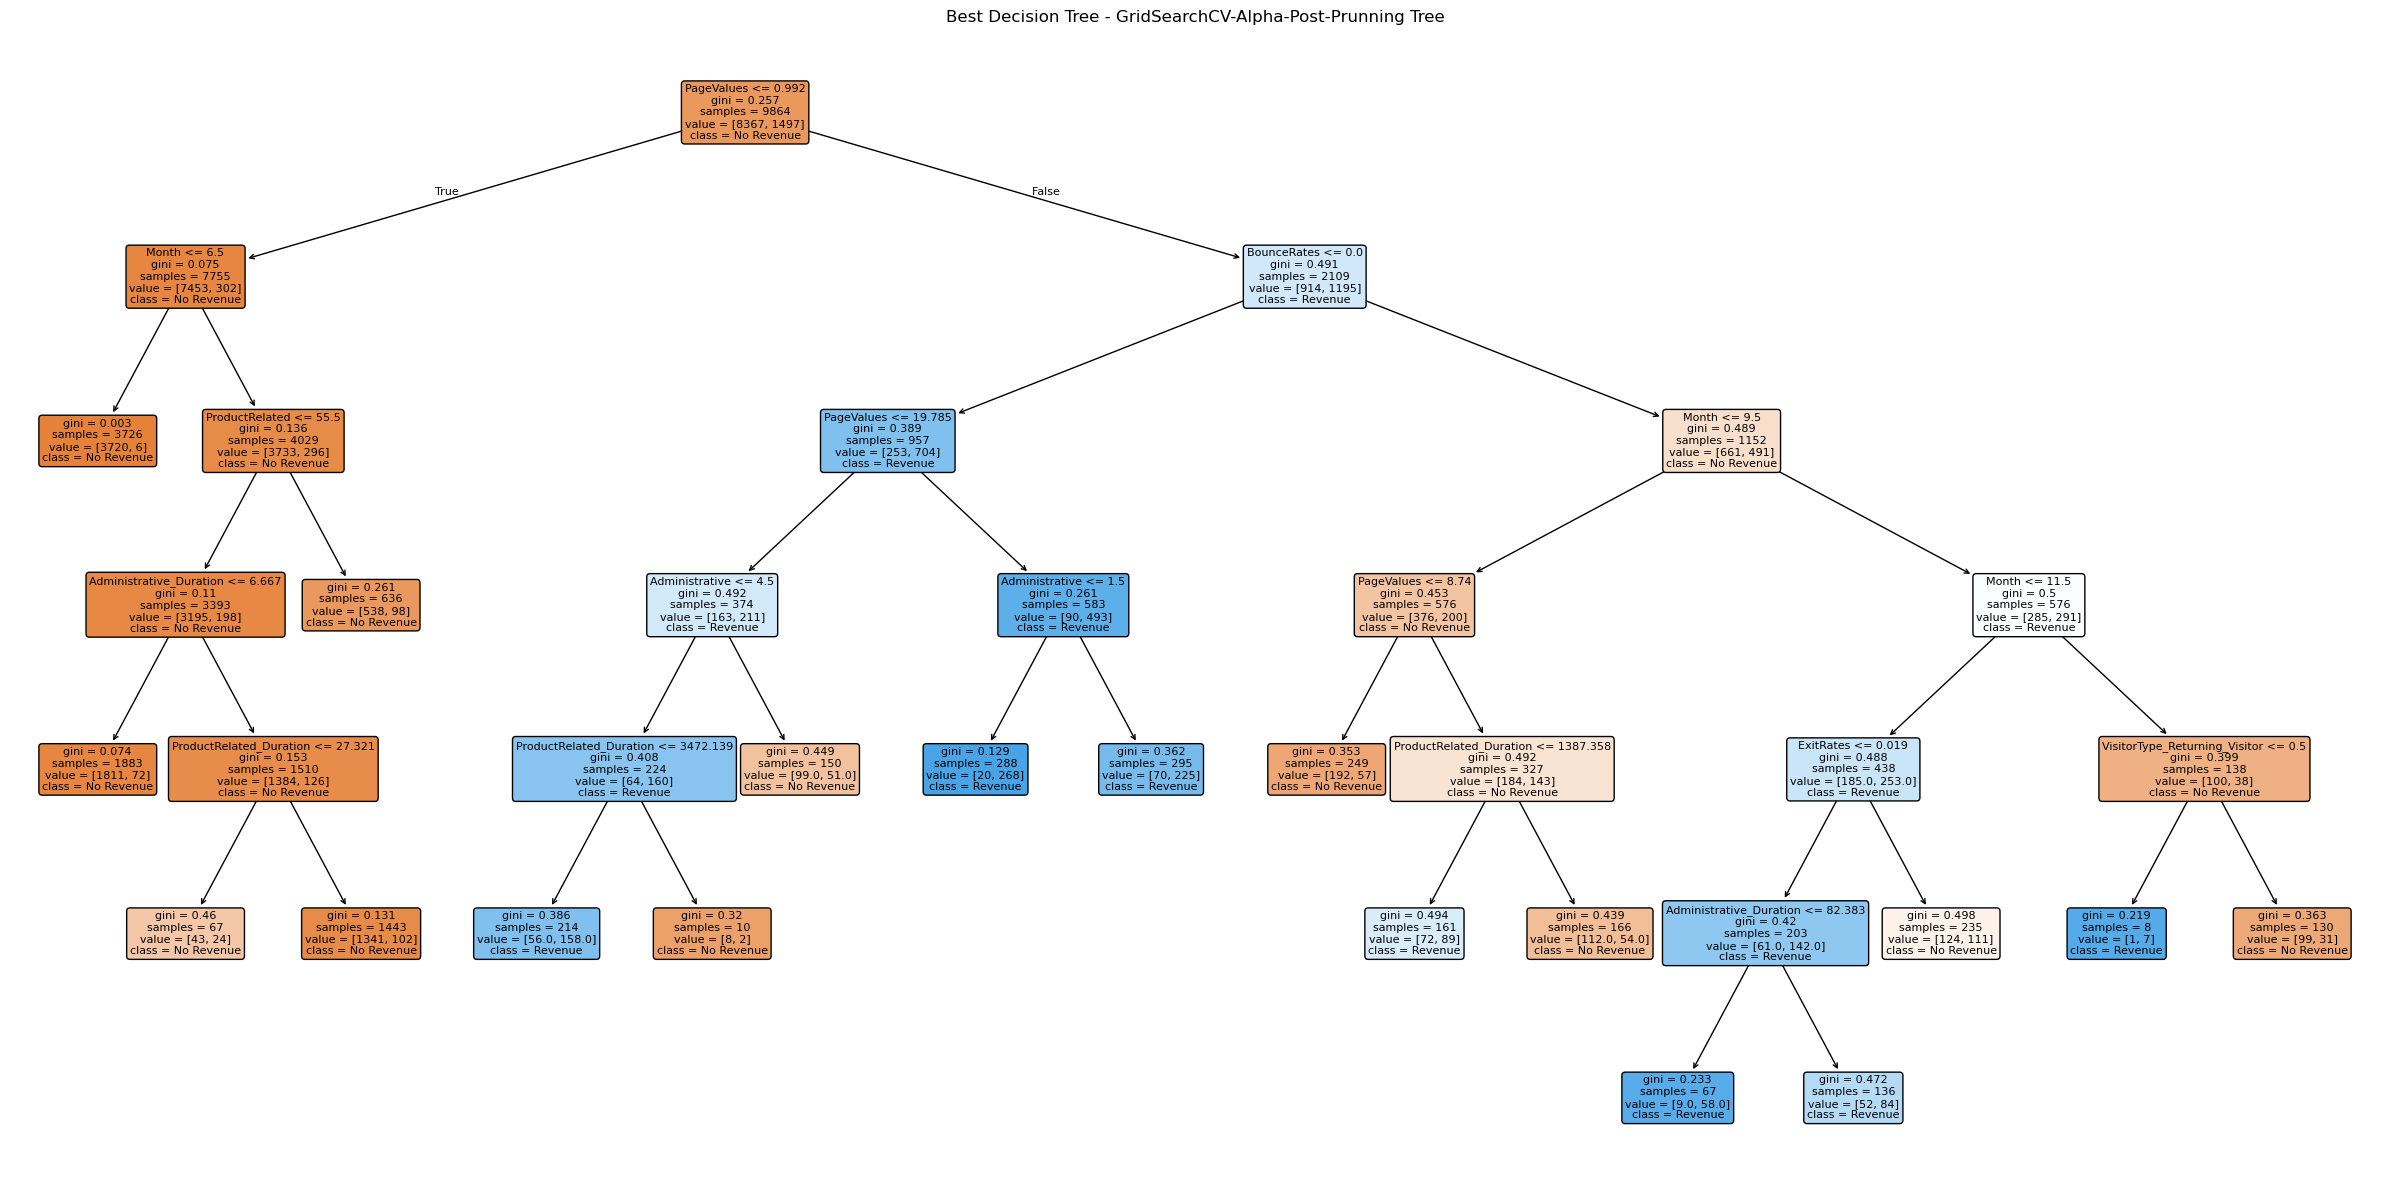

In [106]:
best_model = grid.best_estimator_ # return best model 

# OR create manually new model then fit then test , in this already trainde model 

y_predict = best_model.predict(x_test)

f1 = f1_score(y_test,y_predict)

print("F1-score:", f1*100,"%")


# Plot tree 

plt.figure(figsize=(24, 12))

plot_tree(
    best_model,
    feature_names=x_train.columns,
    class_names=["No Revenue", "Revenue"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Best Decision Tree - GridSearchCV-Alpha-Post-Prunning Tree")
plt.tight_layout()
plt.show()
